# 第11章　協調フィルタリングと行列分解

このノートブックでは、疎行列の基本を確認したあと、Online Retail の購入履歴を使って ALS と BPR の推薦と評価を行います。


In [1]:
import sys
from pathlib import Path

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "doc/src/common/notebook_style.py").exists():
        REPO_ROOT = candidate
        COMMON_ROOT = candidate / "doc/src"
        DATA_PATH = candidate / "doc/02/data/online_retail.csv.gz"
        CHAPTER_DIR = candidate / "doc/11"
        break
    if (candidate / "common/notebook_style.py").exists():
        REPO_ROOT = candidate
        COMMON_ROOT = candidate
        DATA_PATH = candidate / "02/data/online_retail.csv.gz"
        CHAPTER_DIR = candidate / "11"
        break
else:
    raise FileNotFoundError("リポジトリのルートが見つかりません。")

sys.path.insert(0, str(COMMON_ROOT))
from common.notebook_style import apply_dataframe_style

apply_dataframe_style()

## 11.3.1 仮想データを用いた疎行列の確認

行動があったセルだけを保存する COO 形式の疎行列を作り、密行列へ変換して確認します。


In [2]:
import torch

shape = (5, 10)
row_list = [0, 0, 1, 1, 2, 2, 2, 3, 4, 4, 4]
col_list = [1, 4, 3, 9, 2, 5, 6, 3, 0, 4, 9]
indices = [row_list, col_list]
values = [1] * len(row_list)

with torch.sparse.check_sparse_tensor_invariants():
    sparse_matrix = torch.sparse_coo_tensor(indices, values, shape)

print(sparse_matrix)
sparse_matrix.to_dense()

tensor(indices=tensor([[0, 0, 1, 1, 2, 2, 2, 3, 4, 4, 4],
                       [1, 4, 3, 9, 2, 5, 6, 3, 0, 4, 9]]),
       values=tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]),
       size=(5, 10), nnz=11, layout=torch.sparse_coo)


tensor([[0, 1, 0, 0, 1, 0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0, 0, 0, 0, 0, 1],
        [0, 0, 1, 0, 0, 1, 1, 0, 0, 0],
        [0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 1, 0, 0, 0, 0, 1]])

## 11.3.2 Online Retail データの読み込みと整形

UCI Machine Learning Repository の Online Retail を使います。データは CC BY 4.0 で公開されています。

- 作成者: Daqing Chen
- 配布元: https://archive.ics.uci.edu/dataset/352/online+retail
- DOI: https://doi.org/10.24432/C5BW33
- ライセンス: https://creativecommons.org/licenses/by/4.0/
- 加工: 元データをCSV形式に変換し、以下の加工を行います。

キャンセル、返品、顧客 ID がない行、送料などの商品ではない行を除きます。また、新しい商品の推薦を扱うため、同じ顧客と商品の繰り返し購入は最初の1件にまとめます。


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from implicit.als import AlternatingLeastSquares
from implicit.bpr import BayesianPersonalizedRanking
from scipy import sparse
from threadpoolctl import threadpool_limits

plt.rcParams["font.family"] = "Hiragino Sans"

raw_df = pl.read_csv(DATA_PATH, try_parse_dates=True, infer_schema_length=10000)

NON_PRODUCT_CODES = ["POST", "M", "C2", "DOT", "BANK CHARGES"]
clean_df = raw_df.filter(
    pl.col("CustomerID").is_not_null(),
    pl.col("Quantity") > 0,
    pl.col("UnitPrice") > 0,
    ~pl.col("InvoiceNo")
    .cast(pl.String)
    .str.to_uppercase()
    .str.starts_with("C"),
    ~pl.col("StockCode").cast(pl.String).is_in(NON_PRODUCT_CODES),
).unique(maintain_order=True)

df_items = (
    clean_df.filter(pl.col("Description").is_not_null())
    .group_by(["StockCode", "Description"])
    .len()
    .sort(["StockCode", "len"], descending=[False, True])
    .unique("StockCode", keep="first", maintain_order=True)
    .select(
        pl.col("StockCode").cast(pl.String).alias("item_id"),
        pl.col("Description").str.strip_chars().alias("title"),
    )
)

df_before_core = (
    clean_df.sort("InvoiceDate")
    .unique(["CustomerID", "StockCode"], keep="first", maintain_order=True)
    .select(
        pl.col("CustomerID").cast(pl.Int64).cast(pl.String).alias("user_id"),
        pl.col("StockCode").cast(pl.String).alias("item_id"),
        pl.col("InvoiceNo").cast(pl.String).alias("invoice_id"),
        pl.col("InvoiceDate").alias("timestamp"),
    )
)


def iterative_k_core(dataframe, k=5):
    result = dataframe
    while True:
        before = result.shape
        valid_users = (
            result.group_by("user_id")
            .len()
            .filter(pl.col("len") >= k)["user_id"]
        )
        result = result.filter(pl.col("user_id").is_in(valid_users.to_list()))
        valid_items = (
            result.group_by("item_id")
            .len()
            .filter(pl.col("len") >= k)["item_id"]
        )
        result = result.filter(pl.col("item_id").is_in(valid_items.to_list()))
        if result.shape == before:
            return result


df = iterative_k_core(df_before_core, k=5).sort(
    ["user_id", "timestamp", "invoice_id", "item_id"]
)

print(f"元の取引明細数       : {raw_df.height:,}")
print(f"前処理後の取引明細数 : {clean_df.height:,}")
print(f"購入の組み合わせ数   : {df.height:,}")
print(f"顧客数               : {df['user_id'].n_unique():,}")
print(f"商品数               : {df['item_id'].n_unique():,}")

元の取引明細数       : 541,909
前処理後の取引明細数 : 391,153
購入の組み合わせ数   : 264,510
顧客数               : 4,074
商品数               : 3,145


In [4]:
df.head()

user_id,item_id,invoice_id,timestamp
str,str,str,datetime[μs]
"""12347""","""20780""","""537626""",2010-12-07 14:57:00
"""12347""","""20782""","""537626""",2010-12-07 14:57:00
"""12347""","""21064""","""537626""",2010-12-07 14:57:00
"""12347""","""21171""","""537626""",2010-12-07 14:57:00
"""12347""","""21731""","""537626""",2010-12-07 14:57:00


### 行動行列の疎さを確認する


顧客数 |U| = 4,074
商品数 |I| = 3,145
購入ペア数 |O| = 264,510
密度   = 0.0206 (2.06%)
欠損率 = 97.94%


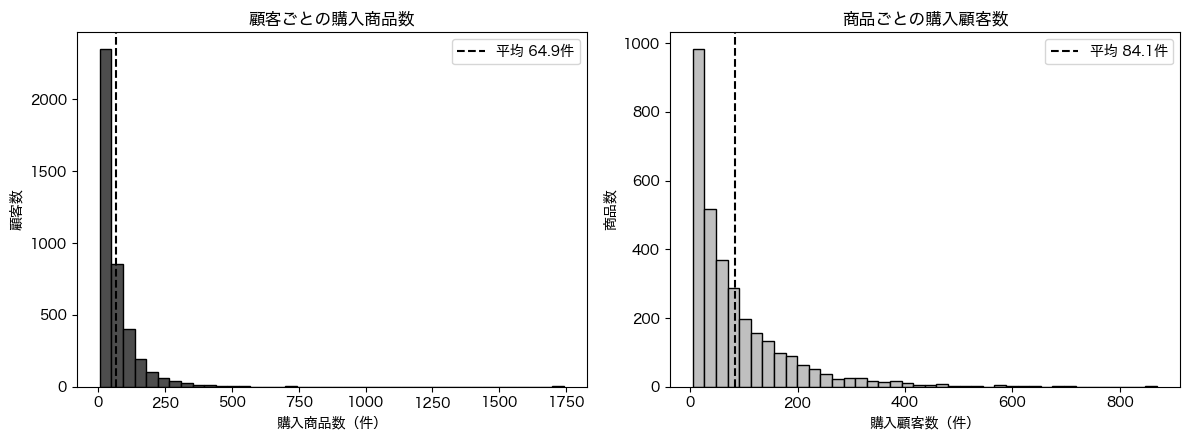

In [5]:
n_users = df["user_id"].n_unique()
n_items = df["item_id"].n_unique()
n_interactions = df.height
density = n_interactions / (n_users * n_items)

print(f"顧客数 |U| = {n_users:,}")
print(f"商品数 |I| = {n_items:,}")
print(f"購入ペア数 |O| = {n_interactions:,}")
print(f"密度   = {density:.4f} ({density * 100:.2f}%)")
print(f"欠損率 = {(1 - density) * 100:.2f}%")

user_counts = df.group_by("user_id").len()["len"].to_numpy()
item_counts = df.group_by("item_id").len()["len"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(user_counts, bins=40, color="0.3", edgecolor="black")
axes[0].axvline(
    user_counts.mean(),
    color="black",
    linestyle="--",
    label=f"平均 {user_counts.mean():.1f}件",
)
axes[0].set(
    title="顧客ごとの購入商品数", xlabel="購入商品数（件）", ylabel="顧客数"
)
axes[0].legend()
axes[1].hist(item_counts, bins=40, color="0.75", edgecolor="black")
axes[1].axvline(
    item_counts.mean(),
    color="black",
    linestyle="--",
    label=f"平均 {item_counts.mean():.1f}件",
)
axes[1].set(
    title="商品ごとの購入顧客数", xlabel="購入顧客数（件）", ylabel="商品数"
)
axes[1].legend()
fig.tight_layout()
plt.show()

### 学習・テストデータへの分割

同じ取引が学習用とテスト用に分かれないよう、顧客ごとに取引をまとめます。そのうえで、古い取引の約80%を学習用、新しい取引の約20%をテスト用にします。取引が1回だけの顧客は学習用に含め、評価対象からは外します。


In [6]:
invoice_df = (
    df.group_by(["user_id", "invoice_id"])
    .agg(pl.col("timestamp").min())
    .sort(["user_id", "timestamp", "invoice_id"])
    .with_columns(
        pl.int_range(pl.len()).over("user_id").alias("invoice_order"),
        pl.len().over("user_id").alias("invoice_count"),
    )
    .with_columns(
        pl.when(pl.col("invoice_count") == 1)
        .then(1)
        .otherwise(
            (pl.col("invoice_count") * 0.8)
            .floor()
            .clip(1, pl.col("invoice_count") - 1)
        )
        .cast(pl.Int64)
        .alias("train_end")
    )
)
split_df = df.join(
    invoice_df.select("user_id", "invoice_id", "invoice_order", "train_end"),
    on=["user_id", "invoice_id"],
)
base_columns = ["user_id", "item_id", "timestamp"]
train_df = split_df.filter(
    pl.col("invoice_order") < pl.col("train_end")
).select(base_columns)
test_df = split_df.filter(
    pl.col("invoice_order") >= pl.col("train_end")
).select(base_columns)

print(f"学習データの購入数 : {train_df.height:,}")
print(f"テストデータの購入数: {test_df.height:,}")
print(f"学習データの顧客数 : {train_df['user_id'].n_unique():,}")
print(f"学習データの商品数 : {train_df['item_id'].n_unique():,}")

学習データの購入数 : 210,600
テストデータの購入数: 53,910
学習データの顧客数 : 4,074
学習データの商品数 : 3,143


In [7]:
train_item_set = set(train_df["item_id"].to_list())
test_item_set = set(test_df["item_id"].to_list())
unknown_items = sorted(test_item_set - train_item_set)
unknown_test_rows = test_df.filter(
    pl.col("item_id").is_in(unknown_items)
).height
test_df = test_df.filter(~pl.col("item_id").is_in(unknown_items))

user_ids = train_df["user_id"].unique().sort().to_list()
item_ids = train_df["item_id"].unique().sort().to_list()
user_id_to_idx = {value: idx for idx, value in enumerate(user_ids)}
item_id_to_idx = {value: idx for idx, value in enumerate(item_ids)}


def add_indices(dataframe):
    return dataframe.with_columns(
        pl.col("user_id")
        .replace_strict(user_id_to_idx, return_dtype=pl.Int32)
        .alias("user_idx"),
        pl.col("item_id")
        .replace_strict(item_id_to_idx, return_dtype=pl.Int32)
        .alias("item_idx"),
    )


train_indexed = add_indices(train_df)
test_indexed = add_indices(test_df)

print(f"学習データにない商品数      : {len(unknown_items):,}")
print(f"評価から除いた購入数        : {unknown_test_rows:,}")
print(f"評価に使うテスト購入数      : {test_df.height:,}")

学習データにない商品数      : 2
評価から除いた購入数        : 16
評価に使うテスト購入数      : 53,894


## 11.3.3 暗黙的フィードバック行列の構築、ALS と BPR の学習

購入した顧客と商品の組み合わせを1とする CSR 形式の疎行列を作ります。


In [8]:
def build_interaction_matrix(dataframe, shape):
    return sparse.csr_matrix(
        (
            np.ones(dataframe.height, dtype=np.float32),
            (
                dataframe["user_idx"].to_numpy(),
                dataframe["item_idx"].to_numpy(),
            ),
        ),
        shape=shape,
    )


matrix_shape = (len(user_ids), len(item_ids))
train_user_item = build_interaction_matrix(train_indexed, matrix_shape)
test_user_item = build_interaction_matrix(test_indexed, matrix_shape)
seen_user_item = train_user_item

print(train_user_item.shape)
print(f"train nnz: {train_user_item.nnz:,}")
print(f"test  nnz: {test_user_item.nnz:,}")

(4074, 3143)
train nnz: 210,600
test  nnz: 53,894


In [9]:
with threadpool_limits(limits=1, user_api="blas"):
    als_model = AlternatingLeastSquares(
        factors=64,
        regularization=0.01,
        iterations=30,
        random_state=42,
        num_threads=1,
    )
    bpr_model = BayesianPersonalizedRanking(
        factors=64,
        learning_rate=0.05,
        regularization=0.01,
        iterations=100,
        random_state=42,
        num_threads=1,
    )
    als_model.fit(train_user_item, show_progress=False)
    bpr_model.fit(train_user_item, show_progress=False)

print("ALS 学習完了")
print("  user_factors:", als_model.user_factors.shape)
print("  item_factors:", als_model.item_factors.shape)
print("BPR 学習完了")
print("  user_factors:", bpr_model.user_factors.shape)
print("  item_factors:", bpr_model.item_factors.shape)

ALS 学習完了
  user_factors: (4074, 64)
  item_factors: (3143, 64)
BPR 学習完了
  user_factors: (4074, 65)
  item_factors: (3143, 65)


## 11.3.4 特定顧客の推薦スコア

顧客 `12347` について、購入済み商品を除いた上位候補を取得します。スコアは購入確率ではなく、順位を決めるための相対値です。


In [10]:
TARGET_UID = "12347"
TOP_N = 5
inner_uid = user_id_to_idx[TARGET_UID]
purchased_inner_iids = set(train_user_item[inner_uid].indices)


def recommend_for_user(model, user_idx, n=5):
    ids, scores = model.recommend(
        user_idx,
        seen_user_item[user_idx],
        N=n,
        filter_already_liked_items=True,
    )
    return (
        pl.DataFrame(
            {
                "item_id": [item_ids[int(iid)] for iid in ids],
                "pred_score": [float(score) for score in scores],
            }
        )
        .join(df_items, on="item_id", how="left")
        .select("item_id", "title", "pred_score")
    )


df_als_top = recommend_for_user(als_model, inner_uid, TOP_N)
df_bpr_top = recommend_for_user(bpr_model, inner_uid, TOP_N)

print(f"対象顧客: {TARGET_UID}")
print(f"学習データ内の購入商品数: {len(purchased_inner_iids)}")
print("\nALS Top-5")
display(df_als_top)
print("BPR Top-5")
display(df_bpr_top)

対象顧客: 12347
学習データ内の購入商品数: 82

ALS Top-5


item_id,title,pred_score
str,str,f64
"""22697""","""GREEN REGENCY TEACUP AND SAUCE…",0.804799
"""22698""","""PINK REGENCY TEACUP AND SAUCER""",0.715422
"""21212""","""PACK OF 72 RETROSPOT CAKE CASE…",0.589598
"""22730""","""ALARM CLOCK BAKELIKE IVORY""",0.58711
"""21977""","""PACK OF 60 PINK PAISLEY CAKE C…",0.431806


BPR Top-5


item_id,title,pred_score
str,str,f64
"""20963""","""APPLE BATH SPONGE""",3.854525
"""79144B""","""PAINTED LIGHTBULB STAR+ MOON""",3.764017
"""22471""","""TV DINNER TRAY AIR HOSTESS""",3.746955
"""47341B""","""BLUE TABLE RUN FLOWER""",3.724156
"""84820""","""DANISH ROSE TRINKET TRAYS""",3.610469


## 11.3.5 上位 N 件の推薦リストとランキング評価


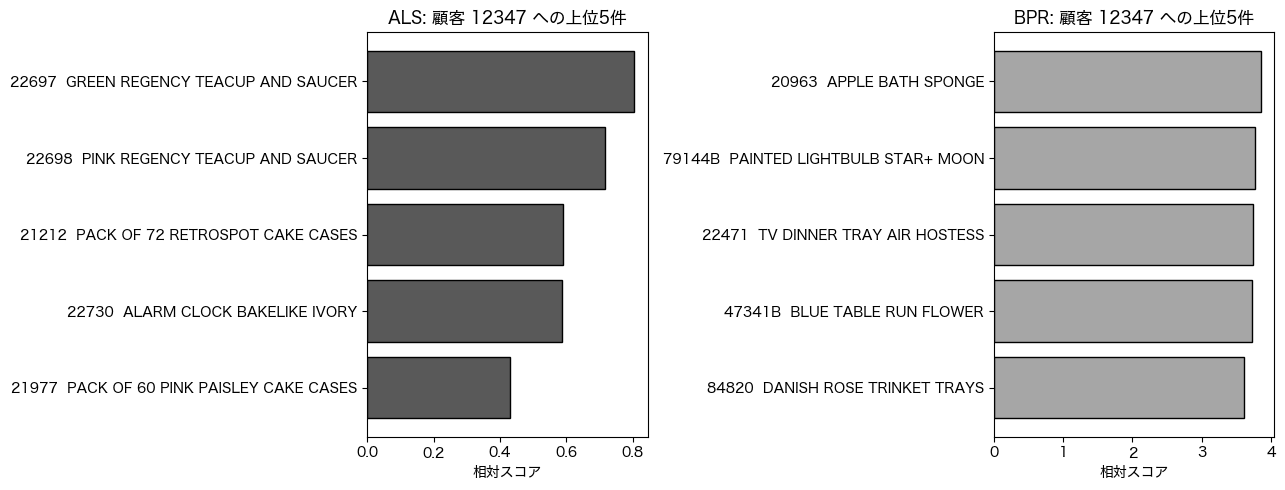

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, data, name, color in [
    (axes[0], df_als_top, "ALS", "0.35"),
    (axes[1], df_bpr_top, "BPR", "0.65"),
]:
    plot_data = data.sort("pred_score")
    labels = [
        f"{row['item_id']}  {row['title']}"
        for row in plot_data.iter_rows(named=True)
    ]
    ax.barh(labels, plot_data["pred_score"], color=color, edgecolor="black")
    ax.set_title(f"{name}: 顧客 {TARGET_UID} への上位{TOP_N}件")
    ax.set_xlabel("相対スコア")
fig.tight_layout()
plt.show()

In [12]:
def build_top_n_dict(model, n=5):
    top_n = {}
    for user_idx, raw_uid in enumerate(user_ids):
        ids, scores = model.recommend(
            user_idx,
            seen_user_item[user_idx],
            N=n,
            filter_already_liked_items=True,
        )
        top_n[raw_uid] = [
            (item_ids[int(iid)], float(score))
            for iid, score in zip(ids, scores)
        ]
    return top_n


als_top_n_all = build_top_n_dict(als_model, TOP_N)
bpr_top_n_all = build_top_n_dict(bpr_model, TOP_N)

In [13]:
def ranking_metrics_at_k(top_n_dict, test_matrix, k=5):
    precisions, recalls, ndcgs = [], [], []
    for raw_uid, ranked_items in top_n_dict.items():
        user_idx = user_id_to_idx[raw_uid]
        relevant_items = set(test_matrix[user_idx].indices)
        if not relevant_items:
            continue
        recommended = [
            item_id_to_idx[item_id] for item_id, _ in ranked_items[:k]
        ]
        hits = [int(item_idx in relevant_items) for item_idx in recommended]
        precisions.append(sum(hits) / k)
        recalls.append(sum(hits) / len(relevant_items))
        dcg = sum(hit / np.log2(rank + 2) for rank, hit in enumerate(hits))
        ideal_count = min(len(relevant_items), k)
        idcg = sum(1 / np.log2(rank + 2) for rank in range(ideal_count))
        ndcgs.append(dcg / idcg)
    return {
        "Precision@K": float(np.mean(precisions)),
        "Recall@K": float(np.mean(recalls)),
        "nDCG@K": float(np.mean(ndcgs)),
        "n_eval_users": len(precisions),
    }


als_metrics = ranking_metrics_at_k(als_top_n_all, test_user_item, TOP_N)
bpr_metrics = ranking_metrics_at_k(bpr_top_n_all, test_user_item, TOP_N)
print("ALS のランキング評価", als_metrics, sep="\n")
print("BPR のランキング評価", bpr_metrics, sep="\n")

ALS のランキング評価
{'Precision@K': 0.08711340206185568, 'Recall@K': 0.038930333117778104, 'nDCG@K': 0.09793636432948666, 'n_eval_users': 2716}
BPR のランキング評価
{'Precision@K': 0.048379970544919, 'Recall@K': 0.026694481541245485, 'nDCG@K': 0.05550199844917624, 'n_eval_users': 2716}


In [14]:
train_pairs = set(zip(train_indexed["user_idx"], train_indexed["item_idx"]))
test_pairs = set(zip(test_indexed["user_idx"], test_indexed["item_idx"]))
assert train_pairs.isdisjoint(test_pairs)
assert all(
    0 <= value <= 1
    for metrics in [als_metrics, bpr_metrics]
    for key, value in metrics.items()
    if key != "n_eval_users"
)
assert als_metrics["n_eval_users"] == bpr_metrics["n_eval_users"] == 2716
assert not purchased_inner_iids.intersection(
    item_id_to_idx[item] for item in df_als_top["item_id"]
)
assert not purchased_inner_iids.intersection(
    item_id_to_idx[item] for item in df_bpr_top["item_id"]
)
print("検証完了: 分割、指標、購入済み商品の除外に問題はありません。")

検証完了: 分割、指標、購入済み商品の除外に問題はありません。
